## Statistics and data

Descriptive statistics on small data sets: what MATLAB's reductions compute, how they treat missing values (`NaN`), and a histogram.

In [ ]:
scores = [12.5 18.2 14.1 22.0 19.8 14.1 16.5 21.3 15.7 17.9];
fprintf('mean %.3f, median %.3f, mode %.1f, std %.3f\n', mean(scores), median(scores), mode(scores), std(scores))
quartiles = prctile(scores, [25 50 75])
z = (scores - mean(scores)) / std(scores);   % z-scores: mean 0, standard deviation 1
fprintf('z-scores from %.3f to %.3f, std %.4f\n', min(z), max(z), std(z))

mean 17.210, median 17.200, mode 14.1, std 3.200



quartiles =

   14.1000   17.2000   19.8000

z-scores from -1.472 to 1.497, std 1.0000


`NaN` marks a missing value. By default it propagates; `'omitnan'` leaves the gaps out. A moving median ignores a spike that pulls a moving mean up.

In [ ]:
daily = [10 NaN 20 30 NaN 25 15];
[mean(daily), mean(daily, 'omitnan'), sum(isnan(daily))]
signal = [1 2 10 4 5 6 7 3 2 8];
smooth = movmean(signal, 3)
robust = movmedian(signal, 3)


ans =

   NaN    20     2


smooth =

  Columns 1 through 7

    1.5000    4.3333    5.3333    6.3333    5.0000    6.0000    5.3333

  Columns 8 through 10

    4.0000    4.3333    5.0000


robust =

  Columns 1 through 7

    1.5000    2.0000    4.0000    5.0000    5.0000    6.0000    6.0000

  Columns 8 through 10

    3.0000    3.0000    5.0000



A thousand normally distributed values (`randn`, with `rng` fixing the sample), in a histogram; then a least-squares line through noisy data with `polyfit`.

correlation 0.928; grade = 4.11 * hours + 50.60


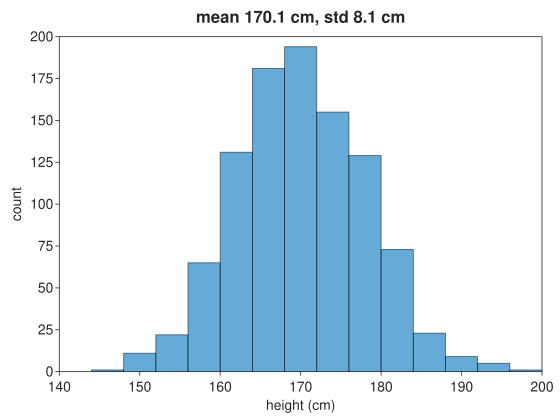

In [ ]:
figure
rng(7);
heights = 170 + 8 * randn(1000, 1);
histogram(heights, 140:4:200), xlabel('height (cm)'), ylabel('count')
title(sprintf('mean %.1f cm, std %.1f cm', mean(heights), std(heights)))
hours = linspace(0, 10, 40)';  grade = 52 + 4.1 * hours + 5 * randn(40, 1);
C = corrcoef(hours, grade);  p = polyfit(hours, grade, 1);
fprintf('correlation %.3f; grade = %.2f * hours + %.2f\n', C(1, 2), p(1), p(2))

In [ ]:
sortrows([3 20; 1 40; 3 10; 2 50], [1 -2])
[vals, ~, idx] = unique([5 2 8 2 5 1]);
[vals; accumarray(idx(:), 1)']


ans =

     1    40
     2    50
     3    20
     3    10




ans =

     1     2     5     8
     1     2     2     1



*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*